        # Welcome · Start Here
        ### Your course map, your toolkit check, and a first graded exercise

        | | |
        |---|---|
        | ⏱️ **Time** | about 45 minutes |
        | 📚 **Before you start** | None: just curiosity |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Verify that your **Python environment** has everything the course needs
- Understand **how every lesson works** (lesson → exercise → hints → check → solution)
- Take a **guided tour of the datasets** you will use for fifteen lessons
- Complete your first auto-graded exercise

> 🌾 **The story so far.** Welcome! I'm glad you're here. Over the next lessons we will forecast the price of tomatoes, onions, maize and potatoes, then build neural networks from scratch and teach them to read handwriting, diagnose sick leaves and forecast markets. My promise: **no magic**. Every idea is built from small pieces you can run, break and fix.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py


warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · The course in one picture

```
PHASE 7  Time-Series Analysis & Forecasting                 PHASE 8  Deep Learning & Neural Networks
─────────────────────────────────────────                   ─────────────────────────────────────────
7.1  What is a time series?                                 8.1  The artificial neuron (NumPy)
7.2  Preparing time-series data                             8.2  Back-propagation from scratch
7.3  The honest scoreboard (metrics, walk-forward)          8.3  PyTorch fundamentals
7.4  Smoothing: MA, SES, Holt, Holt-Winters                 8.4  Training well: optimisers, dropout, early stopping
7.5  ARIMA, SARIMA, SARIMAX                                 8.5  PROJECT 1 · handwritten digits (ANN → CNN)
7.6  ML forecasting: Ridge, RF, GBM, XGBoost                8.6  CNNs up close + augmentation
7.7  Deep-learning forecasting (a first look)               8.7  PROJECT 3 · crop disease classifier
7.8  PRACTICAL ASSIGNMENT · forecasting experiment          8.8  RNN, LSTM, GRU
                                                            8.9  Transformers
                          └──────────────────────┬────────  8.10 Keras & TensorFlow Rosetta Stone
                                                 │          8.11 PROJECT 4 · LSTM price forecasting
                                                 ▼
                     CAPSTONE · The Cooperative's Selling Advisor
                     (forecasts + uncertainty + decisions + a board recommendation)
```

**Suggested pace** (matches your roadmap): Phase 7 ≈ weeks 13–15 (about 8–10 hours/week), Phase 8 ≈ weeks 16–17 (about 12 hours/week), capstone ≈ a long weekend.

## 2 · How every lesson works

| Block | What you do |
|---|---|
| 🎯 **Objectives** | read them first; at the end, tick them off honestly |
| 📖 **Lesson cells** | read, then **run every cell**; change numbers and see what breaks |
| 🤔 **Pause and think** | answer in your head *before* you click the collapsed answer |
| 🧩 **Exercises** | write code in the cell provided; run the **check cell** beneath it |
| 💡 **Hints** | open them **one at a time**; hint 1 is a nudge, the last is almost the answer |
| ✅ **Checks** | green ticks = correct; red ✗ prints a hint. Debugging is the learning |
| 🧾 **Recap & quiz** | explain each bullet aloud in your own words |
| 🔑 **`solutions/` folder** | same notebooks, fully worked: look **after** you've tried for real |

> 🧠 **The learning contract.** If you copy a solution without trying, you learn nothing. If you struggle for 20 minutes, read a hint. If you're stuck after all the hints, read the solution, **close it**, and re-type it from memory tomorrow. That is how skills stick.

### The three rules this whole course is built on
1. **Respect time.** Never shuffle a time series; never let the future leak into the past.
2. **Beat the baseline.** A model is only as good as its margin over "tomorrow = today" (and over a plain linear model).
3. **Report honestly.** Error by horizon, spread across seeds, and what you *don't* know.

## 3 · Toolkit check
Run the next cell. Anything marked ❌ can be installed with `pip install -r requirements.txt` (see the README).

In [2]:
import importlib, platform
need = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "scipy": "scipy", "sklearn": "scikit-learn", "statsmodels": "statsmodels",
        "xgboost": "xgboost", "torch": "torch (PyTorch)", "keras": "keras (optional: Lesson 8.10)", "tensorflow": "tensorflow (optional)"}
print("Python", platform.python_version())
import os
try:
    importlib.import_module("tensorflow")
except Exception:
    os.environ.setdefault("KERAS_BACKEND", "torch")        # Keras 3 can run on PyTorch when TensorFlow is absent
for mod, label in need.items():
    try:
        m = importlib.import_module(mod); print(f"✅ {label:32s} {getattr(m, '__version__', '')}")
    except Exception:
        print(f"{'⚠️ ' if mod in ('keras', 'tensorflow') else '❌'} {label:32s} not installed" + ("  (optional)" if mod in ("keras", "tensorflow") else ""))
try:
    import torch; print("\nGPU available:", torch.cuda.is_available(), "(not required; every notebook runs on a laptop CPU)")
except Exception:
    pass

Python 3.12.3
✅ numpy                            2.5.4
✅ pandas                           3.0.6
✅ matplotlib                       3.11.2
✅ scipy                            1.18.1


✅ scikit-learn                     1.9.1
✅ statsmodels                      0.15.0
✅ xgboost                          3.4.1
✅ torch (PyTorch)                  2.15.0+cu132


✅ keras (optional: Lesson 8.10)    3.15.1
⚠️  tensorflow (optional)            not installed  (optional)

GPU available: False (not required; every notebook runs on a laptop CPU)


## 4 · Meet the data

All data live in the `data/` folder and are **synthetic but realistic**: generated by `src/agrilab.py` from documented ingredients (trend, seasonality, rain effect, fuel cost, shocks, autocorrelated noise).
Because we *know* what we put in, we can check whether our models find it. When you finish, swap in a real dataset: every notebook loads data through two or three helper calls.

| File | Contents | Used in |
|---|---|---|
| `market_prices_daily.csv` | daily wholesale prices: 4 crops × 3 markets × 2015-2024, with volumes and a fuel index | Phase 7, 8.2-8.4, 8.11, capstone |
| `weather_daily.csv` | daily rainfall and temperature (two rainy seasons per year) | exogenous driver in 7.2, 7.5, 7.6, capstone |
| `leaf_disease_synthetic.npz` | 2,400 synthetic 48×48 leaf images, 4 classes | Lesson 8.7 |
| built-in: `sklearn` digits | 1,797 handwritten 8×8 digits | Lessons 8.5, 8.10 |
| generated on the fly | coloured shapes (CNN lesson) | Lesson 8.6 |

**Deliberate messiness** (so you practise real data cleaning): markets are closed on Sundays, ~3-7 % of records are randomly missing, the Highland market had two multi-week outages, and a handful of Highland prices contain decimal-slip typos.

In [3]:
prices = ag.load_prices()
print(prices.shape, "rows |", prices.date.min().date(), "→", prices.date.max().date())
display(prices.head(3)) if "display" in globals() else print(prices.head(3))
print(prices.groupby(["commodity", "market"]).size().unstack())

(35732, 6) rows | 2015-01-01 → 2024-12-31
        date   market commodity  price_per_kg  volume_tonnes  fuel_index
0 2015-01-01  Central     maize         39.82          111.0       100.4
1 2015-01-02  Central     maize         39.44          119.2       101.1
2 2015-01-03  Central     maize         39.29           73.7       101.6
market     Central  Harbor  Highland
commodity                           
maize         3047    2976      2888
onion         3033    3015      2897
potato        3037    3021      2886
tomato        3035    3009      2888


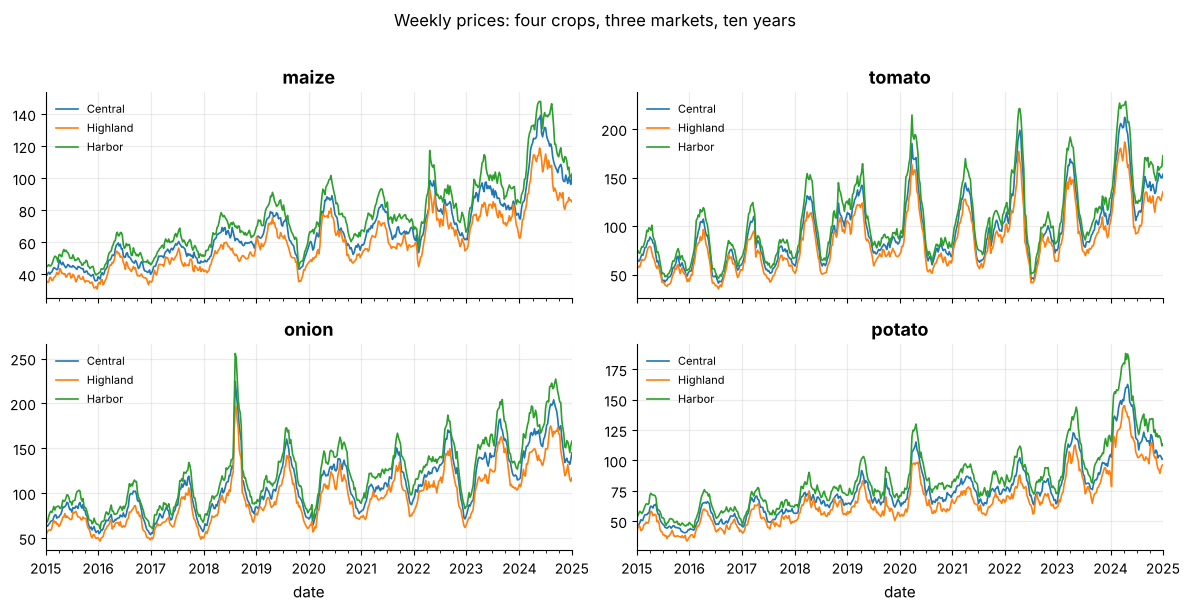

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, com in zip(axes.ravel(), ag.COMMODITIES):
    for mkt in ag.MARKETS:
        ag.price_series(com, mkt, "W").plot(ax=ax, label=mkt, lw=1.2)
    ax.set_title(com); ax.legend(fontsize=8)
plt.suptitle("Weekly prices: four crops, three markets, ten years", y=1.01); plt.tight_layout(); plt.show()

What do you notice? (Write three observations before reading on.) *My list:* a steady upward drift (inflation); a yearly wave whose peak month differs by crop; occasional sudden spikes (shocks);
the three markets move together (shared drivers) but with different levels and noise.

The image data, for later:

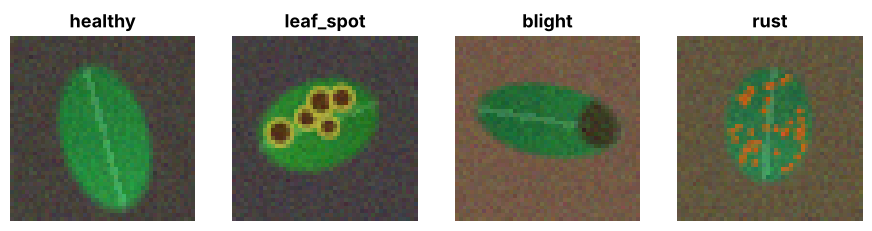

In [5]:
X_leaf, y_leaf, leaf_names = ag.load_leaf_dataset()
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for c, ax in enumerate(axes):
    ax.imshow(X_leaf[np.where(y_leaf == c)[0][0]]); ax.set_title(leaf_names[c]); ax.axis("off")
plt.show()

## 5 · Your first graded exercise
This one checks that **you** and **the autograder** are friends. (Warm-up; ⭐ difficulty.)

---
### 🧩 Exercise 1: Warm-up: ask the data a question  ⭐

Using `prices` (the DataFrame above):
1. `n_rows`: the number of rows;
2. `priciest_crop`: the commodity with the highest **average** `price_per_kg` over the whole table (a string);
3. `tomato_central_2024_mean`: the mean `price_per_kg` for **tomato** at **Central** during calendar year **2024** (a float).

<details><summary>💡 Hint 1: gentle nudge</summary>

`len(prices)` or `prices.shape[0]`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`prices.groupby('commodity')['price_per_kg'].mean()`: then `.idxmax()`. (Heads-up: Highland contains a few absurd typos; do they change the winner?)

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Filter with `prices[(prices.commodity == 'tomato') & (prices.market == 'Central') & (prices.date.dt.year == 2024)]` and take the mean.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
n_rows = None
priciest_crop = None
tomato_central_2024_mean = None

In [ ]:
try:
    ag.check("n_rows is correct", n_rows == len(ag.load_prices()))
    ag.check("priciest_crop is a commodity name", priciest_crop in ag.COMMODITIES)
    ag.check("tomato_central_2024_mean is a plausible price (80 - 250)", tomato_central_2024_mean is not None and 80 < tomato_central_2024_mean < 250)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

## 6 · Study habits of people who finish courses like this
- **Run, then modify.** After each lesson cell, change one thing (a window length, a seed, a learning rate) and predict the result *before* you run it.
- **Keep a lab notebook.** One line per lesson: *"Today I learned… / still confused by…"*.
- **Restart & Run All** at the end of each notebook: it catches hidden-state bugs.
- **Explain it aloud** (rubber-duck debugging): if you can't explain a recap bullet, re-read that section.
- **Rest.** Phase 8 is dense. Sleep consolidates learning more than a fourth hour of staring.

> *"You don't learn to forecast by reading about forecasting. You learn by being embarrassed by a naive baseline (repeatedly) until it stops happening."*

**Next:** open `phase7_timeseries/P7_01_time_series_fundamentals.ipynb`. See you there.

        ---
        ## 🧾 Recap
        - Environment checked; datasets toured; how lessons, hints and solutions work.
- Three rules: **respect time, beat the baseline, report honestly**.

**Next up:** Lesson 7.1: what a time series *is*: trend, seasonality, cycles, noise, stationarity and autocorrelation.